## Final check on fresh holdout data

This notebook answers one practical question: **which of the three selected models should go to the first production release?** It does not tune anything again. Hyperparameters, loss, and seed are fixed; the notebook only tests those fixed choices on more recent days.

The original evaluation ended on June 11, 2026. This notebook adds complete later days from the data sources. It first compares the three optimized candidates, then compares each one with its own simple L2 baseline from notebook 4. This separates a strong model family from a useful optimization.

### What is compared, and why the comparison is fair

The winners from notebook 5 remain: **CatBoost Huber**, **LightGBM L1**, and **XGBoost L1**. Their parameters, training weights, and deployment seed are fixed. There is no new HPO here.

Saved predictions are used for development and the first holdout. The latest holdout starts on **June 12, 2026** and ends on the latest complete source day. Every candidate is scored on exactly the same eligible dates; missing days remain visible in the coverage table.

The first holdout already influenced candidate selection, so the later dates are the stronger new evidence. The combined holdout is a helpful summary, but does not make the old dates independent again.

`p95 absolute error` is the error not exceeded by 95% of 15-minute forecasts. It is not the 95th percentile of daily MAE.

In [ ]:
# Imports and project paths
import hashlib
import importlib
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display
from dotenv import load_dotenv
import pyrootutils

import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = pyrootutils.setup_root(search_from=Path.cwd(), indicator='.gitignore', pythonpath=True)
load_dotenv(PROJECT_ROOT / '.env')

from utils import offshore_final_data as data_tools
from utils import offshore_final_baselines as baseline_tools
from utils import offshore_final_evaluation as evaluation_tools
from utils import offshore_final_plot as plot_tools
importlib.reload(data_tools)
importlib.reload(baseline_tools)
importlib.reload(evaluation_tools)
importlib.reload(plot_tools)

RESULTS_DIR = PROJECT_ROOT / 'results/offshore_final'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
SELECTION_DIR = PROJECT_ROOT / 'results/offshore_joint_loss_hpo/c550de332f450772dce8/selection_d2085702a714cb374154'
ORIGINAL_DATASET = PROJECT_ROOT / 'data/datasets/offshore_dataset_15m_interpolated_14_points_proxy_2024-03-14_to_2026-06-11.parquet'

# These switches control work, not model selection.
UPDATE_SOURCES = True
SAVE_ACTUAL_DATASET = True
RUN_NEW_HOLDOUT = True
RUN_BASELINE_COMPARISON = True  # Notebook-4 controls; results are cached separately.
END_DAY = None                  # None means yesterday in Europe/Berlin; actual coverage is checked below.
REVISION_LOOKBACK_DAYS = 7      # Request recent generation again to pick up corrections.
MAX_CAPACITY_AGE_DAYS = 62      # Explicit carry-forward policy, not a publication guarantee.
MAX_SOURCE_REQUESTS = None      # Set to 1 for a small API check; None fills every gap.
MAX_NEW_EVALUATION_DAYS = None  # Set to 1 for a timing check; None evaluates all eligible days.
MAX_MISSING_TRAIN_DAYS = 3      # Drop up to three incomplete days inside the 365-day window.
MODEL_THREADS = min(4, os.cpu_count() or 1)
evaluation_tools.N_THREADS = MODEL_THREADS
pd.set_option('display.max_columns', None)

# Fixed winner configurations used throughout this notebook.
selection = json.loads((SELECTION_DIR / 'frozen_selection.json').read_text(encoding='utf-8'))
if hashlib.sha256(ORIGINAL_DATASET.read_bytes()).hexdigest() != selection['dataset_hash']:
    raise ValueError('The original dataset differs from the frozen notebook-5 snapshot.')
FEATURE_COLS = selection['fit_protocol']['features']
original_dataset = pd.read_parquet(ORIGINAL_DATASET)
print('Deployment seed:', selection['deployment_seed'])
print('Threads per model:', MODEL_THREADS)
print('\n=== Fixed candidate configurations ===')
display(pd.DataFrame([{'model': name, **config['model_params'], 'loss': config['loss'],
                      'huber_delta': config['huber_delta'], 'weighting': config['weighting'],
                      'weight_alpha': config['weight_alpha'], 'weight_power': config['weight_power']}
                     for name, config in selection['best_by_model'].items()]))

Deployment seed: 1337
Threads per model: 4

=== Fixed candidate configurations ===


,model,depth,iterations,l2_leaf_reg,learning_rate,random_strength,rsm,subsample,loss,huber_delta,weighting,weight_alpha,weight_power,colsample_bytree,max_depth,min_child_samples,n_estimators,num_leaves,reg_alpha,reg_lambda,gamma,min_child_weight
0,CatBoost,7.0,1600.0,41.156575,0.017136,1.461253,0.788873,0.923939,huber,0.076474,capacity_factor,2.953206,1.193698,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LightGBM,NaN,NaN,NaN,0.051601,NaN,NaN,0.700020,l1,NaN,uniform,0.000000,1.000000,0.881517,7.0,811.0,235.0,83.0,0.0,0.039450,NaN,NaN
2,XGBoost,NaN,NaN,NaN,0.033720,NaN,NaN,0.760389,l1,NaN,uniform,0.000000,1.000000,0.751497,6.0,NaN,612.0,NaN,0.0,0.338198,0.002215,127.146679


### Updating the input data

Each source has its own cache, so a temporary source failure cannot remove valid earlier data.

- **ECMWF:** target day D uses the D-1 00Z run. The run must include all 14 points and a complete time grid.
- **Actual generation:** old gaps and recent days are requested again to capture possible ENTSO-E corrections. A partial response may add data, but cannot erase cached values.
- **Installed capacity:** the latest monthly value can be carried forward for at most `MAX_CAPACITY_AGE_DAYS`; its age is recorded.

Yesterday is only the requested upper bound, not proof that all sources have published a full day. This is a retrospective backtest using data available now, not a reconstruction of historical source versions.

In [22]:
# Running this cell again checks for missing data and recent corrections.
# Each successful source update is saved immediately, before model evaluation.
weather_features, generation, capacity, source_events, requested_end = data_tools.refresh_sources(
    PROJECT_ROOT, end_day=END_DAY, update=UPDATE_SOURCES,
    revision_days=REVISION_LOOKBACK_DAYS, max_requests=MAX_SOURCE_REQUESTS,
)
print('\n=== Source update status ===')
print('Requested last target day:', requested_end.date())
print('Cached generation through:', generation.index.max())
print('Latest capacity effective date:', capacity.dt_utc.max())
print('Source update events')
display(source_events)
source_events.to_csv(RESULTS_DIR / 'source_events.csv', index=False)

Generation 2026-09-30: 96/96 intervals
Generation 2026-10-02: 96/96 intervals
Generation 2026-10-03: 96/96 intervals
Generation 2026-10-04: 96/96 intervals
Run range 2026-06-23 → 2026-06-23 (ECMWF IFS HRES, height 100 m)
  Target for each run: calendar day D+1 in Europe/Berlin
  (23 hours at spring DST, 25 at autumn DST, otherwise 24), ±1-hour buffer

  [Single Run | ecmwf_ifs] run 2026-06-23T00:00, 14 points...

✅ Total: 364 rows, 14 points.
   NaN wind_speed     : 0 (0.0%)
   Duplicate natural keys (point_id, datetime_run_utc, datetime_utc): 0
   Height (height_m):
height_m
100    364
   Rows per (point_id, run), distribution:
26    14

=== Source update status ===
Requested last target day: 2026-10-04
Cached generation through: 2026-10-04 21:45:00+00:00
Latest capacity effective date: 2026-10-01 00:00:00+00:00
Source update events


,source,day,status,detail
0,capacity,2026-10-05,updated,NaN
1,generation,2026-09-28,ReadTimeout,NaN
2,generation,2026-09-29,ReadTimeout,NaN
3,generation,2026-09-30,received 96/96,NaN
4,generation,2026-10-01,ReadTimeout,NaN
5,generation,2026-10-02,received 96/96,NaN
6,generation,2026-10-03,received 96/96,NaN
7,generation,2026-10-04,received 96/96,NaN
8,weather,2026-06-24,ValueError,"Incomplete ECMWF run: missing values in temp, ..."


### Using the same features for old and new days

`utils/offshore_final_features.py` repeats the feature work from notebook 1b: it turns weather data into wind speed and direction, power proxies, regional risk features, calendar features, and forecast lead time.

Feature outputs are cached. They are rebuilt only when the raw forecast or transformation code changes. All 14 points are checked before aggregation so a regional average cannot silently hide a missing point.

Data through June 11 are kept unchanged because saved historical predictions used that snapshot. Source corrections apply only to the new part.

In [23]:
# Keep every requested new timestamp, including rows with unavailable sources.
# Coverage flags are metadata and are never passed to the model as features.
actual_dataset, daily_coverage = data_tools.assemble_dataset(
    original_dataset, weather_features, generation, capacity, requested_end,
    FEATURE_COLS, max_capacity_age_days=MAX_CAPACITY_AGE_DAYS, source_events=source_events,
)
complete_days = daily_coverage.index[daily_coverage.row_complete]
latest_complete_day = complete_days.max() if len(complete_days) else None
print('Latest complete new day:', latest_complete_day)
print('Complete / requested new days:', len(complete_days), '/', len(daily_coverage))
print('\nNew-day source coverage')
display(daily_coverage)
print('Incomplete or unavailable days')
display(daily_coverage.loc[~daily_coverage.row_complete])

# A gap remains a gap; the latest complete date does not imply continuous coverage.
if SAVE_ACTUAL_DATASET:
    # The name describes the target, resolution, weather feature family and local-date coverage.
    datasets_dir = PROJECT_ROOT / 'data/datasets'
    local_index = actual_dataset.index.tz_convert(data_tools.TZ)
    coverage_tag = f'{local_index.min().date()}_to_{local_index.max().date()}'
    dataset_stem = f'offshore_cf_15m_ecmwf14p_engineered_{coverage_tag}'
    dataset_path = datasets_dir / f'{dataset_stem}.parquet'
    coverage_path = datasets_dir / f'{dataset_stem}_daily_coverage.parquet'
    metadata_path = datasets_dir / f'{dataset_stem}_metadata.json'
    data_tools.save_parquet(actual_dataset, dataset_path)
    data_tools.save_parquet(daily_coverage, coverage_path)
    metadata = {
        'retrieved_at_utc': str(pd.Timestamp.now(tz='UTC')),
        'requested_end': str(requested_end.date()),
        'latest_complete_day': str(latest_complete_day),
        'complete_new_days': len(complete_days),
        'original_dataset_sha256': selection['dataset_hash'],
        'dataset_hash': data_tools.frame_hash(actual_dataset),
        'feature_columns': FEATURE_COLS,
        'revision_lookback_days': REVISION_LOOKBACK_DAYS,
        'max_missing_train_days': MAX_MISSING_TRAIN_DAYS,
        'max_capacity_age_days': MAX_CAPACITY_AGE_DAYS,
        'source_version_note': 'Current revisions; exact historical publication times are unknown.',
    }
    metadata.update(dataset_path=str(dataset_path.relative_to(PROJECT_ROOT)),
                    coverage_path=str(coverage_path.relative_to(PROJECT_ROOT)))
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
    print('Saved final dataset:', dataset_path.relative_to(PROJECT_ROOT))

Latest complete new day: 2026-10-04 00:00:00
Complete / requested new days: 114 / 115

New-day source coverage


,weather_available,generation_available,capacity_available,target_valid,row_complete,expected_rows,complete_rows,reason
day,,,,,,,,
2026-06-12,True,True,True,True,True,96,96,
2026-06-13,True,True,True,True,True,96,96,
2026-06-14,True,True,True,True,True,96,96,
2026-06-15,True,True,True,True,True,96,96,
2026-06-16,True,True,True,True,True,96,96,
...,...,...,...,...,...,...,...,...
2026-09-30,True,True,True,True,True,96,96,
2026-10-01,True,True,True,True,True,96,96,
2026-10-02,True,True,True,True,True,96,96,


Incomplete or unavailable days


,weather_available,generation_available,capacity_available,target_valid,row_complete,expected_rows,complete_rows,reason
day,,,,,,,,
2026-06-24,False,True,True,True,False,96,0,"Incomplete ECMWF run: missing values in temp, ..."


Saved final dataset: data\datasets\offshore_cf_15m_ecmwf14p_engineered_2024-03-15_to_2026-10-04.parquet


### Saved results for development and the first holdout

This loads the exact winner configurations from the frozen selection file, along with their saved development and first-holdout predictions. All periods use deployment seed `1337`, so development values can differ slightly from the two-seed ranking in notebook 5.

Loading these files does not fit a model. The code checks that their dates and actual values match the frozen source dataset.

In [24]:
previous_predictions = evaluation_tools.load_previous_predictions(SELECTION_DIR, selection)
reference = original_dataset.copy()
reference.index = pd.to_datetime(reference.index, utc=True)
for model_name, predictions in previous_predictions.groupby('model'):
    times = pd.to_datetime(predictions.target_time, utc=True)
    np.testing.assert_allclose(predictions.actual, reference.capacity_factor.reindex(times), rtol=0, atol=1e-12)
print('\nSaved predictions by historical period')
display(previous_predictions.groupby(['model', 'period']).agg(
    start=('day', 'min'), end=('day', 'max'), days=('day', 'nunique'), rows=('row', 'size')))



Saved predictions by historical period


start         end  days   rows
model    period                                            
CatBoost development    2025-03-16  2026-05-14   425  40796
         first_holdout  2026-05-15  2026-06-11    28   2688
LightGBM development    2025-03-16  2026-05-14   425  40796
         first_holdout  2026-05-15  2026-06-11    28   2688
XGBoost  development    2025-03-16  2026-05-14   425  40796
         first_holdout  2026-05-15  2026-06-11    28   2688

### New holdout: daily refits

For target day D, every model trains on the preceding 365 calendar days; the final training day is D-2. This is the notebook-5 protocol. Parameters are fixed and are not selected using the target day.

The target day must be complete. Up to `MAX_MISSING_TRAIN_DAYS = 3` incomplete days may be removed from the training window. They are removed in full, without interpolation and without extending the window backward. More missing days skip the target day; the audit table records why.

The first run can take time because there are three fits per eligible new day. The cache allows an interrupted run to resume without retraining completed days.

In [25]:
if RUN_NEW_HOLDOUT:
    latest_predictions, evaluation_audit = evaluation_tools.evaluate_new_days(
        actual_dataset, selection, RESULTS_DIR / 'prediction_cache', daily_coverage.index,
        max_days=MAX_NEW_EVALUATION_DAYS, max_missing_train_days=MAX_MISSING_TRAIN_DAYS,
    )
    data_tools.save_parquet(latest_predictions, RESULTS_DIR / 'latest_predictions.parquet')
    evaluation_audit.to_csv(RESULTS_DIR / 'evaluation_audit.csv', index=False)
else:
    # Do not load a previous result without checking its dataset identity.
    latest_predictions = pd.DataFrame()
    evaluation_audit = pd.DataFrame()
    print('New holdout evaluation is disabled; only historical periods will be shown.')
print('\nLatest-holdout evaluation audit')
display(evaluation_audit)
if not latest_predictions.empty:
    print('New evaluated days:', latest_predictions.day.nunique())
    print('Eligible complete days:', len(complete_days))
    if latest_predictions.day.nunique() < len(complete_days):
        print('PARTIAL evaluation: inspect the day limit and skipped-day audit before interpreting scores.')

New holdout days: 100%|██████████| 115/115 [00:11<00:00,  9.69it/s]


Latest-holdout evaluation audit


,day,model,status,reason,train_days,dropped_train_days,dropped_train_dates,train_rows,expected_train_rows,cache_hit,fit_seconds
0,2026-06-12,CatBoost,evaluated,,365,0,,35040,35040,True,19.589220
1,2026-06-12,LightGBM,evaluated,,365,0,,35040,35040,True,0.598485
2,2026-06-12,XGBoost,evaluated,,365,0,,35040,35040,True,4.354960
3,2026-06-13,CatBoost,evaluated,,365,0,,35040,35040,True,18.995512
4,2026-06-13,LightGBM,evaluated,,365,0,,35040,35040,True,0.607996
...,...,...,...,...,...,...,...,...,...,...,...
338,2026-10-03,LightGBM,evaluated,,364,1,2026-06-24,34944,35040,True,0.584174
339,2026-10-03,XGBoost,evaluated,,364,1,2026-06-24,34944,35040,True,4.195209
340,2026-10-04,CatBoost,evaluated,,364,1,2026-06-24,34944,35040,True,18.639110
341,2026-10-04,LightGBM,evaluated,,364,1,2026-06-24,34944,35040,True,0.574203


New evaluated days: 114
Eligible complete days: 114


### Main metrics by period

The table shows development, first holdout, latest holdout, and their combination. Combined-holdout metrics are recalculated from all 15-minute forecasts together, not averaged from the two tables.

The main selection metric is mean daily `MAE`: lower is better for a typical day. `RMSE` and `p95 absolute error` react more to large misses. `bias` shows systematic over-prediction (positive) or under-prediction (negative). `high-CF MAE` uses only actual CF >= 0.6; with few such days it is supporting evidence, not a stand-alone decision rule.

The standard deviation of daily MAE describes day-to-day variation, not a confidence interval.

In [26]:
metrics_table, all_predictions = evaluation_tools.comparison_table(previous_predictions, latest_predictions)
metrics_table.to_csv(RESULTS_DIR / 'period_metrics.csv', index=False)
print('\nFull candidate metrics by period')
display(metrics_table)
print('\nMean daily MAE, quick comparison')
display(metrics_table.pivot(index=['model', 'loss'], columns='period', values='mae_mean'))

# Show how the target distribution changes between periods.
unique_targets = all_predictions.drop_duplicates(['period', 'row'])
print('\nActual CF mix by period')
display(unique_targets.groupby('period').agg(
    days=('day', 'nunique'), mean_cf=('actual', 'mean'),
    high_cf_rows=('actual', lambda values: int(values.ge(0.6).sum())),
    maximum_cf=('actual', 'max')))



Full candidate metrics by period


,model,loss,period,start,end,mae_mean,mae_std,seed_mae_std,seed_mae_min,seed_mae_max,rmse_pooled,r2_pooled,bias,p95_absolute_error,high_cf_mae,high_cf_rows,high_cf_days,target_rows,target_days,n_seeds,raw_outside_fraction,raw_prediction_min,raw_prediction_max,mean_fit_seconds,train_mae,validation_minus_train_mae,timing_days
0,CatBoost,huber,development,2025-03-16,2026-05-14,0.064704,0.035962,None,0.064704,0.064704,0.088675,0.854417,-0.000102,0.188388,0.087445,7273,196,40796,425,1,0.002819,-0.035797,0.774205,NaN,NaN,NaN,0
1,LightGBM,l1,development,2025-03-16,2026-05-14,0.064434,0.035444,None,0.064434,0.064434,0.088282,0.855706,-0.005442,0.187488,0.090043,7273,196,40796,425,1,0.001863,-0.008345,0.787999,NaN,NaN,NaN,0
2,XGBoost,l1,development,2025-03-16,2026-05-14,0.065641,0.037681,None,0.065641,0.065641,0.090209,0.849340,-0.006667,0.191739,0.092499,7273,196,40796,425,1,0.001569,-0.011077,0.803428,NaN,NaN,NaN,0
3,CatBoost,huber,first_holdout,2026-05-15,2026-06-11,0.047881,0.030626,None,0.047881,0.047881,0.069993,0.827177,0.006083,0.142478,0.072708,34,2,2688,28,1,0.011905,-0.013620,0.594851,NaN,NaN,NaN,0
4,LightGBM,l1,first_holdout,2026-05-15,2026-06-11,0.052246,0.031995,None,0.052246,0.052246,0.074729,0.803000,0.000328,0.157937,0.085859,34,2,2688,28,1,0.005208,-0.002427,0.581752,NaN,NaN,NaN,0
5,XGBoost,l1,first_holdout,2026-05-15,2026-06-11,0.049460,0.030081,None,0.049460,0.049460,0.070910,0.822619,-0.000153,0.155394,0.077465,34,2,2688,28,1,0.000744,-0.000476,0.600859,NaN,NaN,NaN,0
6,CatBoost,huber,latest_holdout,2026-06-12,2026-10-04,0.068188,0.051510,None,0.068188,0.068188,0.099372,0.617005,0.036351,0.230053,0.127154,172,14,10944,114,1,0.000091,-0.000431,0.640417,18.289967,0.040717,0.027471,114
7,LightGBM,l1,latest_holdout,2026-06-12,2026-10-04,0.065714,0.049769,None,0.065714,0.065714,0.096207,0.641012,0.030443,0.225828,0.130106,172,14,10944,114,1,0.000914,-0.002051,0.629674,0.521757,0.045104,0.020610,114
8,XGBoost,l1,latest_holdout,2026-06-12,2026-10-04,0.064812,0.048602,None,0.064812,0.064812,0.094335,0.654845,0.029115,0.217737,0.136099,172,14,10944,114,1,0.000000,0.001164,0.674115,3.799175,0.031230,0.033582,114
9,CatBoost,huber,combined_holdout,2026-05-15,2026-10-04,0.064184,0.048700,None,0.064184,0.064184,0.094306,0.661760,0.030382,0.218225,0.118168,206,16,13632,142,1,0.002421,-0.013620,0.640417,18.289967,0.040717,NaN,114



Mean daily MAE, quick comparison


,period,combined_holdout,development,first_holdout,latest_holdout
model,loss,,,,
CatBoost,huber,0.064184,0.064704,0.047881,0.068188
LightGBM,l1,0.063058,0.064434,0.052246,0.065714
XGBoost,l1,0.061785,0.065641,0.049460,0.064812



Actual CF mix by period


,days,mean_cf,high_cf_rows,maximum_cf
period,,,,
development,425,0.334342,7273,0.865240
first_holdout,28,0.218691,34,0.673997
latest_holdout,114,0.224467,172,0.765244


### Did optimization improve each family over its simple baseline?

Each optimized configuration is matched with its notebook-4 control: a 365-day window, daily refit, L2 loss, uniform weights, and 200 trees. Candidate and baseline use the same target rows, actual values, and seed.

A positive `*_gain_pct` means the optimized version is better; a negative value means it is worse. This comparison shows whether the selected loss and HPO add value beyond the model family itself.

New holdout days: 100%|██████████| 115/115 [00:11<00:00,  9.99it/s]



Candidates and L2 baselines on matched dates


,period,model,configuration,loss,mae_mean,mae_std,mae_mean_gain_pct,rmse_pooled,rmse_pooled_gain_pct,bias,p95_absolute_error,high_cf_mae,high_cf_mae_gain_pct,high_cf_rows,target_days,mean_fit_seconds
0,development,CatBoost,hpo_selected,huber,0.0647,0.0360,4.3082,0.0887,3.5509,-0.0001,0.1884,0.0874,12.2365,7273,425,NaN
1,development,CatBoost,notebook4_baseline,l2,0.0676,0.0378,0.0000,0.0919,0.0000,-0.0069,0.1952,0.0996,0.0000,7273,425,NaN
6,first_holdout,CatBoost,hpo_selected,huber,0.0479,0.0306,3.8500,0.0700,2.6542,0.0061,0.1425,0.0727,29.9623,34,28,NaN
7,first_holdout,CatBoost,notebook4_baseline,l2,0.0498,0.0308,0.0000,0.0719,0.0000,-0.0024,0.1524,0.1038,0.0000,34,28,NaN
12,latest_holdout,CatBoost,hpo_selected,huber,0.0682,0.0515,-2.7446,0.0994,-3.6124,0.0364,0.2301,0.1272,15.3246,172,114,18.2900
13,latest_holdout,CatBoost,notebook4_baseline,l2,0.0664,0.0481,0.0000,0.0959,0.0000,0.0301,0.2192,0.1502,0.0000,172,114,0.9394
18,combined_holdout,CatBoost,hpo_selected,huber,0.0642,0.0487,-1.7184,0.0943,-2.8726,0.0304,0.2182,0.1182,17.0845,206,142,18.2900
19,combined_holdout,CatBoost,notebook4_baseline,l2,0.0631,0.0456,0.0000,0.0917,0.0000,0.0237,0.2106,0.1425,0.0000,206,142,0.9394
2,development,LightGBM,hpo_selected,l1,0.0644,0.0354,4.0257,0.0883,3.6658,-0.0054,0.1875,0.0900,5.4087,7273,425,NaN
3,development,LightGBM,notebook4_baseline,l2,0.0671,0.0379,0.0000,0.0916,0.0000,-0.0066,0.1932,0.0952,0.0000,7273,425,NaN



Optimization gain versus L2 baseline (%)


mae_mean_gain_pct                                                \
period         development first_holdout latest_holdout combined_holdout   
model                                                                      
CatBoost          4.308223      3.850025      -2.744601        -1.718360   
LightGBM          4.025691     -3.954763       0.130855        -0.514533   
XGBoost           1.732720      0.401327       1.452709         1.288228   

         rmse_pooled_gain_pct                                                \
period            development first_holdout latest_holdout combined_holdout   
model                                                                         
CatBoost             3.550910      2.654230      -3.612449        -2.872637   
LightGBM             3.665803     -3.313479      -0.985116        -1.276799   
XGBoost              1.205283      0.741963       1.190748         1.136382   

         high_cf_mae_gain_pct                                                
period            development first_holdout latest_holdout combined_holdout  
model                                                                        
CatBoost            12.236522     29.962320      15.324611        17.084450  
LightGBM             5.408695     -8.676521      11.502109         9.564413  
XGBoost              2.925761      5.350760       3.378379         3.581582

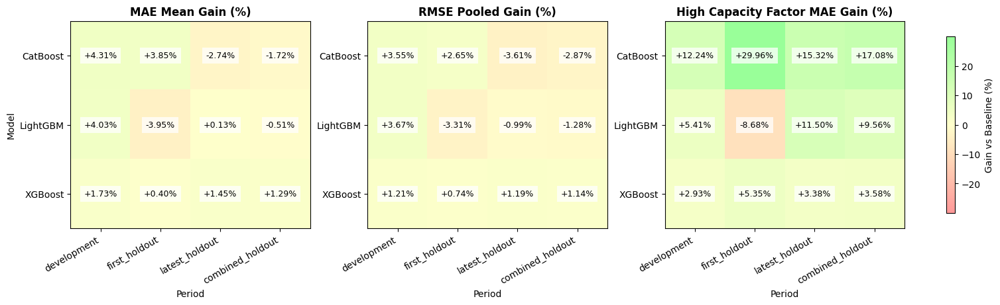

In [27]:
baseline_selection = baseline_tools.baseline_selection(selection)
baseline_previous = baseline_tools.load_previous_predictions(SELECTION_DIR, selection)

if not RUN_BASELINE_COMPARISON:
    raise RuntimeError('Set RUN_BASELINE_COMPARISON = True to build the matched final table.')

baseline_latest, baseline_audit = evaluation_tools.evaluate_new_days(
    actual_dataset, baseline_selection, RESULTS_DIR / 'baseline_prediction_cache',
    daily_coverage.index, max_days=MAX_NEW_EVALUATION_DAYS,
    max_missing_train_days=MAX_MISSING_TRAIN_DAYS,
)
data_tools.save_parquet(baseline_latest, RESULTS_DIR / 'baseline_latest_predictions.parquet')
baseline_audit.to_csv(RESULTS_DIR / 'baseline_evaluation_audit.csv', index=False)
baseline_metrics, baseline_all_predictions = evaluation_tools.comparison_table(
    baseline_previous, baseline_latest,
)

# Guard against a tempting but invalid comparison on different dates.
for period in ['development', 'first_holdout', 'latest_holdout']:
    for model_name in selection['best_by_model']:
        tuned_rows = set(all_predictions.loc[
            all_predictions.period.eq(period) & all_predictions.model.eq(model_name), 'row'])
        baseline_rows = set(baseline_all_predictions.loc[
            baseline_all_predictions.period.eq(period) & baseline_all_predictions.model.eq(model_name), 'row'])
        if tuned_rows != baseline_rows:
            raise ValueError(f'Unmatched comparison rows: {model_name}, {period}')

tuned_metrics = metrics_table.assign(configuration='hpo_selected')
baseline_metrics = baseline_metrics.assign(configuration='notebook4_baseline')
final_metrics_table = pd.concat([tuned_metrics, baseline_metrics], ignore_index=True)
reference = baseline_metrics[['model', 'period', 'mae_mean', 'rmse_pooled', 'high_cf_mae']].rename(
    columns={name: f'{name}_baseline' for name in ['mae_mean', 'rmse_pooled', 'high_cf_mae']})
final_metrics_table = final_metrics_table.merge(reference, on=['model', 'period'], validate='many_to_one')
for metric in ['mae_mean', 'rmse_pooled', 'high_cf_mae']:
    final_metrics_table[f'{metric}_gain_pct'] =  100 * (1 - final_metrics_table[metric] / final_metrics_table[f'{metric}_baseline'])
period_order = ['development', 'first_holdout', 'latest_holdout', 'combined_holdout']
final_metrics_table['period'] = pd.Categorical(
    final_metrics_table.period, categories=period_order, ordered=True)
final_metrics_table = final_metrics_table.sort_values(['period', 'model', 'configuration']).reset_index(drop=True)
final_metrics_table.to_csv(RESULTS_DIR / 'period_metrics_with_baselines.csv', index=False)

decision_columns = [
    'period', 'model', 'configuration', 'loss', 'mae_mean', 'mae_std',
    'mae_mean_gain_pct', 'rmse_pooled',
    'rmse_pooled_gain_pct', 'bias', 'p95_absolute_error',
    'high_cf_mae', 'high_cf_mae_gain_pct',
    'high_cf_rows', 'target_days', 'mean_fit_seconds',
]
print('\nCandidates and L2 baselines on matched dates')
display(final_metrics_table[decision_columns].sort_values(by=['model', 'period', 'configuration']).round(4))

# Positive values below mean that HPO improved on the simple L2 control.
hpo_gain_table = final_metrics_table.loc[
    final_metrics_table.configuration.eq('hpo_selected'),
    ['model', 'period', 'mae_mean_gain_pct',
     'rmse_pooled_gain_pct', 'high_cf_mae_gain_pct'],
].pivot(index='model', columns='period')
print('\nOptimization gain versus L2 baseline (%)')
display(hpo_gain_table)


# The pivot uses a two-level column index: metric, then period.
metrics = hpo_gain_table.columns.levels[0]

from matplotlib.colors import LinearSegmentedColormap

# Red means worse than the baseline; green means better.
light_pnl = LinearSegmentedColormap.from_list(
    "light_pnl", ["#ff9999", "#ffffcc", "#99ff99"]
)

# Keep the three decision metrics in one consistently scaled heatmap.
metrics_info = [
    ('mae_mean_gain_pct', 'MAE Mean Gain (%)'),
    ('rmse_pooled_gain_pct', 'RMSE Pooled Gain (%)'),
    ('high_cf_mae_gain_pct', 'High Capacity Factor MAE Gain (%)')
]

# One panel per metric makes trade-offs easier to scan.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

models = list(hpo_gain_table.index)
periods = list(hpo_gain_table.columns.levels[1])

for col, (metric, title) in enumerate(metrics_info):
    ax = axes[col]
    grid = hpo_gain_table[metric]
    
    # A shared symmetric scale makes colors comparable across panels.
    color_limit = float(np.nanmax(np.abs(hpo_gain_table.to_numpy(dtype=float)))) or 1.0
    low, high = -color_limit, color_limit  # Shared scale; yellow means zero gain.
    
    # Draw the model-by-period gain table.
    im = ax.imshow(grid, cmap=light_pnl, vmin=low, vmax=high, aspect="auto")
    
    # Label each panel so it remains readable outside the notebook context.
    ax.set_xticks(range(len(periods)), periods, rotation=30, ha='right')
    ax.set_yticks(range(len(models)), models)
    ax.set_xlabel("Period")
    ax.set_ylabel("Model" if col == 0 else "")
    ax.set_title(title, fontsize=12, fontweight='bold')
    
    # Add exact values because color is only a quick visual cue.
    for i in range(len(models)):
        for j in range(len(periods)):
            val = grid.iloc[i, j]
            ax.text(
                j, i, f"{val:+.2f}%", 
                ha="center", va="center", color="black", fontsize=9,
                bbox=dict(facecolor="white", alpha=0.75, edgecolor="none")
            )

fig.colorbar(im, ax=axes.tolist(), shrink=0.85, label="Gain vs Baseline (%)")

plt.show()

### Check: is the result only caused by a different Capacity Factor mix?

This section compares existing optimized and baseline predictions on the same dates. Positive `gain = baseline MAE - optimized MAE` favors the optimized model. No models are fitted here.

Errors are first grouped into CF bins of width 0.1. Both periods are then given the same bin weights. If the conclusion changes, part of the difference may be explained by a different mix of low and high generation. Only bins with enough observations are used, and their coverage is shown.

The final table matches every 28-day latest-holdout block to 28 development days with a similar actual-CF distribution. This is **not a full year-over-year test** or new independent validation. It only checks whether the result is similar under a comparable CF mix; similar CF does not guarantee similar weather or forecast difficulty.

In [28]:
from utils import offshore_cf_diagnostics as cf_tools
importlib.reload(cf_tools)

# Use the predictions already loaded above; this does not touch fit caches.
cf_pairs = cf_tools.paired_errors(all_predictions, baseline_all_predictions)
cf_bins = cf_tools.bin_metrics(cf_pairs)
cf_mix = cf_tools.mix_comparison(cf_pairs, cf_bins)
cf_windows = cf_tools.matched_windows(cf_pairs)
CF_RESULTS_DIR = RESULTS_DIR / 'cf_diagnostics'
CF_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
for name, table in [('bin_errors', cf_bins), ('target_mix', cf_mix), ('matched_windows', cf_windows)]:
    table.to_csv(CF_RESULTS_DIR / f'{name}.csv', index=False)

# Check the full population before comparing conditional errors.
cf_population = cf_pairs.drop_duplicates(['period', 'row'])
print('\nCF sample size and composition')
display(cf_population.groupby('period').agg(
    intervals=('row', 'size'), days=('day', 'nunique'), mean_cf=('actual', 'mean'),
    high_cf_share=('actual', lambda x: x.ge(.6).mean())).round(4))
print('\nEffect of equalizing the CF distribution')
display(cf_mix[['model', 'period', 'bins_used', 'development_mass', 'holdout_mass',
    'raw_daily_gain', 'raw_pooled_gain', 'development_gain_shared', 'holdout_gain_shared',
    'holdout_gain_development_mix', 'development_gain_holdout_mix',
    'mix_effect', 'within_bin_effect']].round(5))
print('\nMatched 28-day CF windows')
display(cf_windows.round(5))



CF sample size and composition


,intervals,days,mean_cf,high_cf_share
period,,,,
development,40796,425,0.3343,0.1783
first_holdout,2688,28,0.2187,0.0126
latest_holdout,10944,114,0.2245,0.0157



Effect of equalizing the CF distribution


,model,period,bins_used,development_mass,holdout_mass,raw_daily_gain,raw_pooled_gain,development_gain_shared,holdout_gain_shared,holdout_gain_development_mix,development_gain_holdout_mix,mix_effect,within_bin_effect
0,CatBoost,first_holdout,"0.0–0.1, 0.1–0.2, 0.2–0.3, 0.3–0.4, 0.4–0.5, 0...",0.82172,0.98735,0.00192,0.00192,0.00090,0.00154,0.00231,0.00073,-0.00077,0.00141
1,CatBoost,latest_holdout,"0.0–0.1, 0.1–0.2, 0.2–0.3, 0.3–0.4, 0.4–0.5, 0...",0.93039,0.99845,-0.00182,-0.00182,0.00212,-0.00190,0.00064,0.00084,-0.00254,-0.00148
2,LightGBM,first_holdout,"0.0–0.1, 0.1–0.2, 0.2–0.3, 0.3–0.4, 0.4–0.5, 0...",0.82172,0.98735,-0.00199,-0.00199,0.00217,-0.00193,-0.00197,0.00195,0.00005,-0.00414
3,LightGBM,latest_holdout,"0.0–0.1, 0.1–0.2, 0.2–0.3, 0.3–0.4, 0.4–0.5, 0...",0.93039,0.99845,0.00009,0.00009,0.00262,0.00003,0.00173,0.00187,-0.00170,-0.00089
4,XGBoost,first_holdout,"0.0–0.1, 0.1–0.2, 0.2–0.3, 0.3–0.4, 0.4–0.5, 0...",0.82172,0.98735,0.00020,0.00020,0.00081,0.00015,-0.00010,0.00090,0.00025,-0.00091
5,XGBoost,latest_holdout,"0.0–0.1, 0.1–0.2, 0.2–0.3, 0.3–0.4, 0.4–0.5, 0...",0.93039,0.99845,0.00096,0.00096,0.00096,0.00094,0.00080,0.00093,0.00015,-0.00016



Matched 28-day CF windows


,model,period,holdout_start,holdout_end,development_start,development_end,histogram_distance,development_mean_cf,holdout_mean_cf,development_high_cf_share,holdout_high_cf_share,holdout_days,development_daily_gain,holdout_daily_gain,holdout_mae_baseline,holdout_mae_hpo
0,CatBoost,first_holdout,2026-05-15,2026-06-11,2026-04-09,2026-05-06,0.05506,0.21182,0.21869,0.00893,0.01265,28,0.00058,0.00192,0.04980,0.04788
1,LightGBM,first_holdout,2026-05-15,2026-06-11,2026-04-09,2026-05-06,0.05506,0.21182,0.21869,0.00893,0.01265,28,-0.00049,-0.00199,0.05026,0.05225
2,XGBoost,first_holdout,2026-05-15,2026-06-11,2026-04-09,2026-05-06,0.05506,0.21182,0.21869,0.00893,0.01265,28,0.00008,0.00020,0.04966,0.04946
3,CatBoost,latest_holdout,2026-06-12,2026-07-09,2026-04-09,2026-05-06,0.04259,0.21182,0.21164,0.00893,0.02778,27,0.00058,-0.00473,0.06562,0.07035
4,LightGBM,latest_holdout,2026-06-12,2026-07-09,2026-04-09,2026-05-06,0.04259,0.21182,0.21164,0.00893,0.02778,27,-0.00049,-0.00220,0.06579,0.06799
5,XGBoost,latest_holdout,2026-06-12,2026-07-09,2026-04-09,2026-05-06,0.04259,0.21182,0.21164,0.00893,0.02778,27,0.00008,0.00182,0.06637,0.06455
6,CatBoost,latest_holdout,2026-07-10,2026-08-06,2026-04-05,2026-05-02,0.02307,0.23220,0.23254,0.02976,0.03199,28,0.00140,0.00070,0.05347,0.05277
7,LightGBM,latest_holdout,2026-07-10,2026-08-06,2026-04-05,2026-05-02,0.02307,0.23220,0.23254,0.02976,0.03199,28,-0.00011,0.00108,0.05337,0.05229
8,XGBoost,latest_holdout,2026-07-10,2026-08-06,2026-04-05,2026-05-02,0.02307,0.23220,0.23254,0.02976,0.03199,28,-0.00003,0.00040,0.05312,0.05272
9,CatBoost,latest_holdout,2026-08-07,2026-09-03,2025-06-26,2025-07-23,0.04725,0.23008,0.22601,0.04278,0.00521,28,0.00221,-0.00052,0.05178,0.05230


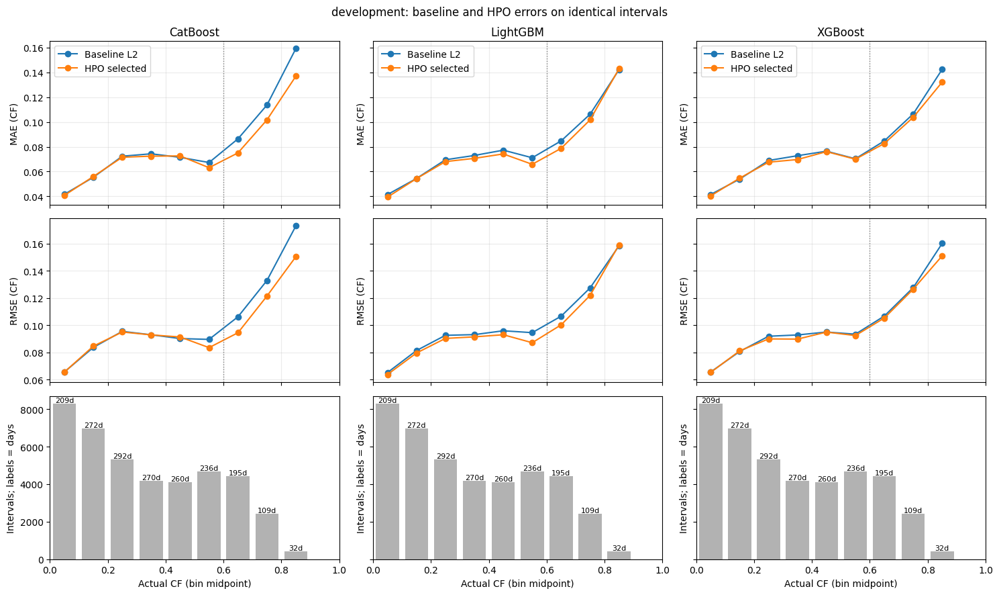

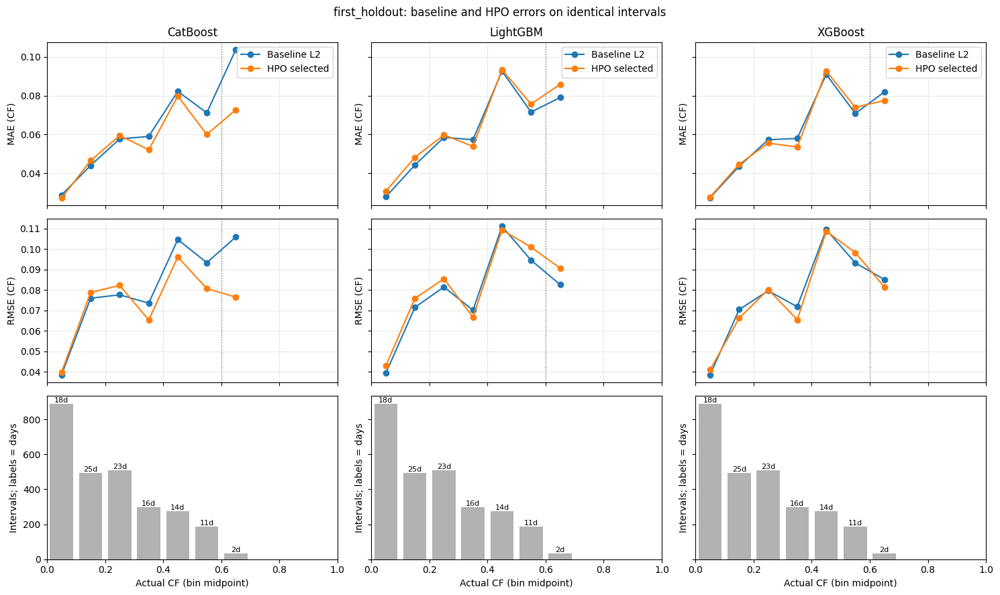

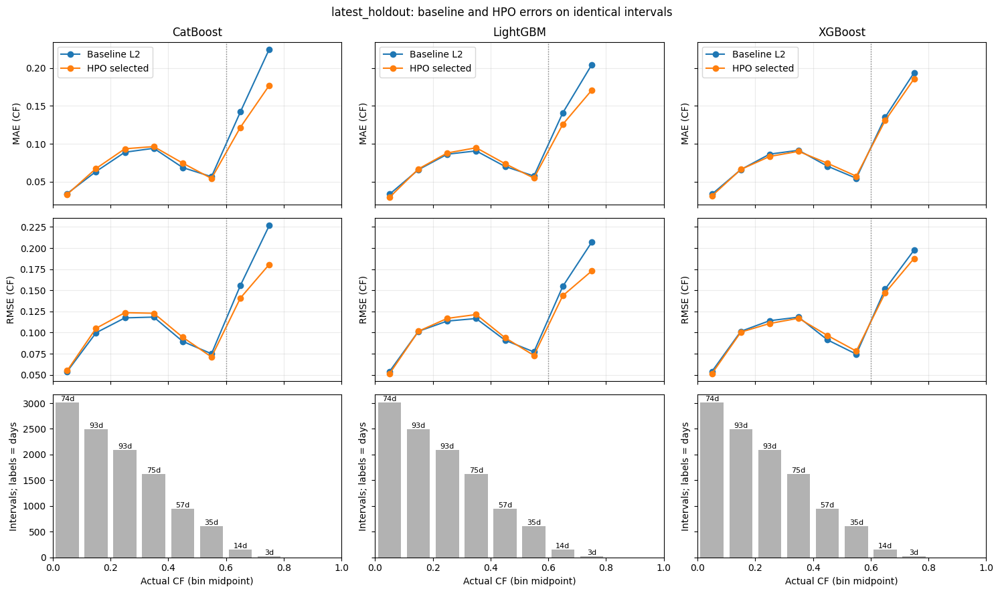

CatBoost | first_holdout: HPO gain +0.00154; with development bin weights +0.00231. Change from development: mix -0.00077, within-bin +0.00141.
CatBoost | latest_holdout: HPO gain -0.00190; with development bin weights +0.00064. Change from development: mix -0.00254, within-bin -0.00148.
LightGBM | first_holdout: HPO gain -0.00193; with development bin weights -0.00197. Change from development: mix +0.00005, within-bin -0.00414.
LightGBM | latest_holdout: HPO gain +0.00003; with development bin weights +0.00173. Change from development: mix -0.00170, within-bin -0.00089.
XGBoost | first_holdout: HPO gain +0.00015; with development bin weights -0.00010. Change from development: mix +0.00025, within-bin -0.00091.
XGBoost | latest_holdout: HPO gain +0.00094; with development bin weights +0.00080. Change from development: mix +0.00015, within-bin -0.00016.


In [29]:
# Compare baseline/HPO error curves; counts show where evidence is sparse.
for cf_period in ['development', 'first_holdout', 'latest_holdout']:
    cf_figure = cf_tools.error_figure(cf_bins, cf_period)
    cf_figure.savefig(CF_RESULTS_DIR / f'{cf_period}_errors.png', dpi=150, bbox_inches='tight')
    plt.show()

# Read the decomposition on shared support, not as a new deployment score.
for row in cf_mix.itertuples():
    print(f'{row.model} | {row.period}: HPO gain {row.holdout_gain_shared:+.5f}; '
          f'with development bin weights {row.holdout_gain_development_mix:+.5f}. '
          f'Change from development: mix {row.mix_effect:+.5f}, '
          f'within-bin {row.within_bin_effect:+.5f}.')


### How to read the CF and matched-window checks

A positive gain favors optimization. If the sign changes after using development CF weights, the different CF mix matters. `within_bin_effect` shows the change inside the same CF ranges; a negative value means optimization became worse even without a mix change.

Snapshot through **October 4, 2026**: XGBoost's latest-holdout gain barely changes after CF reweighting (`+0.00094` to `+0.00093` pooled MAE). Mix effects and within-bin changes nearly cancel, so CF mix does not explain its result. CatBoost still worsens inside comparable bins. LightGBM remains slightly positive after reweighting, but its raw gain is near zero.

XGBoost wins against its baseline in three of four complete matched 28-day blocks and is almost tied in the fourth. This supports the choice, but does not prove causality or statistical significance.

## Decision for the first production release

**I decided to choose XGBoost with L1 as the first model for production.** It is the most consistent candidate on data through October 4, 2026.

On the latest holdout (114 days), XGBoost has the best mean daily MAE: **0.06481**, versus **0.06571** for LightGBM and **0.06819** for CatBoost. It also has the best RMSE (`0.09434`) and p95 error (`0.21774`). It remains first on the combined holdout: MAE **0.06178**, versus `0.06306` and `0.06418`.

Most importantly, optimized XGBoost improves MAE over its own L2 baseline in every slice: development **+1.73%**, first holdout **+0.40%**, latest holdout **+1.45%**, and combined holdout **+1.29%**. CatBoost gets worse on the latest holdout; LightGBM's optimization effect is almost zero. CF reweighting barely changes the XGBoost gain.

In addition, I manually reviewed the forecasts from all the models on the interactive chart below. Subjectively, I also lean towards XGB, as it better predicted sharp drops in generation based on the actual data.

The gain is moderate and high-CF observations remain limited. CatBoost is still best at CF >= 0.6, but loses overall accuracy, large-error control and bias. LightGBM is about seven times faster to refit (`~0.52 s` vs `~3.76 s` per day), but that saving does not outweigh XGBoost accuracy for a daily run.

### Prediction chart and data gaps

The chart shows all three fixed candidates on one timeline. Red lines separate the first and latest holdouts; the range slider is useful for difficult days and sharp generation drops.

Grey bands are days without forecasts. Labels state the reason, such as a missing ECMWF run, incomplete weather data, or missing generation. `Evaluation not run` means scoring was not performed, not necessarily that a source failed. The table below the chart contains the same intervals and full reasons.

This notebook evaluates history. Production still needs a day-ahead path without future actuals, a persistent source cache, and scheduled GitHub Actions.

In [30]:
# Use the full requested timeline, including days without forecasts.
figure, forecast_gaps = plot_tools.prediction_chart(
    all_predictions, actual_dataset, daily_coverage, evaluation_audit, selection,
)
forecast_gaps.to_csv(RESULTS_DIR / 'forecast_gaps.csv', index=False)
print('\nForecast gaps and reasons')
display(forecast_gaps)
figure.write_html(RESULTS_DIR / 'combined_predictions.html', include_plotlyjs=True)
figure.show()


Forecast gaps and reasons


,start,end,reason,label
0,2026-06-24,2026-06-25,"Incomplete ECMWF run: missing values in temp, ...",Incomplete ECMWF data


### Running the notebook again

Use the project Python environment. A fresh environment can install dependencies with `python -m pip install -r requirements-offshore-final.txt`. The ENTSO-E key is read from `ENTSOE_API_KEY` and is never written into the notebook or result tables.

By default the notebook requests available data and evaluates every eligible new day. For a short check, set `MAX_SOURCE_REQUESTS = 1` and `MAX_NEW_EVALUATION_DAYS = 1`; restore both to `None` for the complete comparison. Use `UPDATE_SOURCES = False` offline.

Reusable logic lives in `utils`, so a future GitHub Actions workflow can call the same data preparation, evaluation, and baseline code. Before release, run the full notebook once and record the snapshot date.